In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_theme(style="whitegrid", palette="mako", font_scale=1.1)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Georgia", "DejaVu Serif", "Times New Roman"]

color_acento = "#2c7fb8"
color_secundario = "#d95f0e"

In [ ]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("esgaritus/resultados-icfes-2019-2025")
archivo = os.path.join(path, "df_icfes_historico (full).csv")

cols = [
    "punt_global", "periodo",
    "cole_depto_ubicacion",
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_situacioneconomica",
    "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter", "cole_jornada",
    "estu_genero", "estu_horassemanatrabaja",
]

df = pd.read_csv(archivo, usecols=cols, low_memory=False)

print("Valores únicos de periodo:", sorted(df["periodo"].unique()))

df["anio"] = df["periodo"].astype(str).str[:4].astype(int)
df = df[df["anio"] >= 2022].reset_index(drop=True)

def arreglar_mojibake(texto):
    if isinstance(texto, str):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

for col in cols:
    df[col] = df[col].apply(arreglar_mojibake)

print("Filas totales (2022-2025):", df.shape[0])
df.head(10)

Using Colab cache for faster access to the 'resultados-icfes-2019-2025' dataset.
Valores únicos de periodo: [np.int64(20191), np.int64(20192), np.int64(20201), np.int64(20202), np.int64(20211), np.int64(20212), np.int64(20221), np.int64(20222), np.int64(20231), np.int64(20232), np.int64(20241), np.int64(20242), np.int64(20251), np.int64(20252)]
Filas totales (2022-2025): 2681025


,periodo,cole_area_ubicacion,cole_caracter,cole_depto_ubicacion,cole_jornada,cole_naturaleza,estu_genero,estu_horassemanatrabaja,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_numlibros,fami_personashogar,fami_situacioneconomica,fami_tieneinternet,punt_global,anio
0,20221,URBANO,ACADÉMICO,ANTIOQUIA,SABATINA,NO OFICIAL,M,Menos de 10 horas,Tres,No sabe,No sabe,Estrato 2,11 A 25 LIBROS,3 a 4,Mejor,Si,163,2022
1,20221,URBANO,ACADÉMICO,LA GUAJIRA,COMPLETA,NO OFICIAL,M,Entre 21 y 30 horas,NaN,Educación profesional completa,Educación profesional completa,Estrato 3,MÁS DE 100 LIBROS,3 a 4,Mejor,Si,313,2022
2,20221,URBANO,TÉCNICO/ACADÉMICO,BOGOTÁ,COMPLETA,NO OFICIAL,F,0,Tres,Educación profesional completa,Educación profesional completa,Estrato 5,26 A 100 LIBROS,3 a 4,Igual,Si,324,2022
3,20221,URBANO,ACADÉMICO,ANTIOQUIA,SABATINA,NO OFICIAL,F,Entre 11 y 20 horas,Tres,Primaria completa,Primaria incompleta,Estrato 2,26 A 100 LIBROS,3 a 4,Igual,Si,166,2022
4,20221,URBANO,NaN,CUNDINAMARCA,SABATINA,NO OFICIAL,F,Menos de 10 horas,Dos,Secundaria (Bachillerato) completa,Secundaria (Bachillerato) incompleta,Estrato 2,0 A 10 LIBROS,3 a 4,Igual,Si,222,2022
5,20221,URBANO,ACADÉMICO,BOGOTÁ,COMPLETA,NO OFICIAL,F,0,Tres,Educación profesional completa,Postgrado,Estrato 6,26 A 100 LIBROS,3 a 4,Igual,Si,295,2022
6,20221,URBANO,NaN,CORDOBA,SABATINA,NO OFICIAL,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,207,2022
7,20221,RURAL,ACADÉMICO,CUNDINAMARCA,COMPLETA,NO OFICIAL,M,Entre 11 y 20 horas,Cuatro,Educación profesional completa,Educación profesional completa,Estrato 5,MÁS DE 100 LIBROS,3 a 4,Mejor,Si,268,2022
8,20221,RURAL,NO APLICA,VALLE,SABATINA,NO OFICIAL,F,Entre 11 y 20 horas,Dos,Técnica o tecnológica incompleta,Educación profesional completa,Estrato 3,11 A 25 LIBROS,3 a 4,Igual,Si,252,2022
9,20221,URBANO,ACADÉMICO,BOGOTÁ,NOCHE,NO OFICIAL,M,Menos de 10 horas,Cuatro,Secundaria (Bachillerato) incompleta,No sabe,Estrato 3,11 A 25 LIBROS,9 o más,Igual,Si,229,2022


In [ ]:
df.info()
df.isnull().mean().sort_values(ascending=False) * 100  # % de nulos por columna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2681025 entries, 0 to 2681024
Data columns (total 18 columns):
 #   Column                   Dtype 
---  ------                   ----- 
 0   periodo                  int64 
 1   cole_area_ubicacion      object
 2   cole_caracter            object
 3   cole_depto_ubicacion     object
 4   cole_jornada             object
 5   cole_naturaleza          object
 6   estu_genero              object
 7   estu_horassemanatrabaja  object
 8   fami_cuartoshogar        object
 9   fami_educacionmadre      object
 10  fami_educacionpadre      object
 11  fami_estratovivienda     object
 12  fami_numlibros           object
 13  fami_personashogar       object
 14  fami_situacioneconomica  object
 15  fami_tieneinternet       object
 16  punt_global              int64 
 17  anio                     int64 
dtypes: int64(3), object(15)
memory usage: 368.2+ MB


,0
fami_numlibros,23.529285
fami_tieneinternet,21.914268
fami_educacionmadre,21.651309
fami_educacionpadre,21.610802
fami_situacioneconomica,20.554191
estu_horassemanatrabaja,20.174709
fami_cuartoshogar,19.766358
fami_personashogar,19.583853
cole_caracter,19.058159
fami_estratovivienda,17.804459


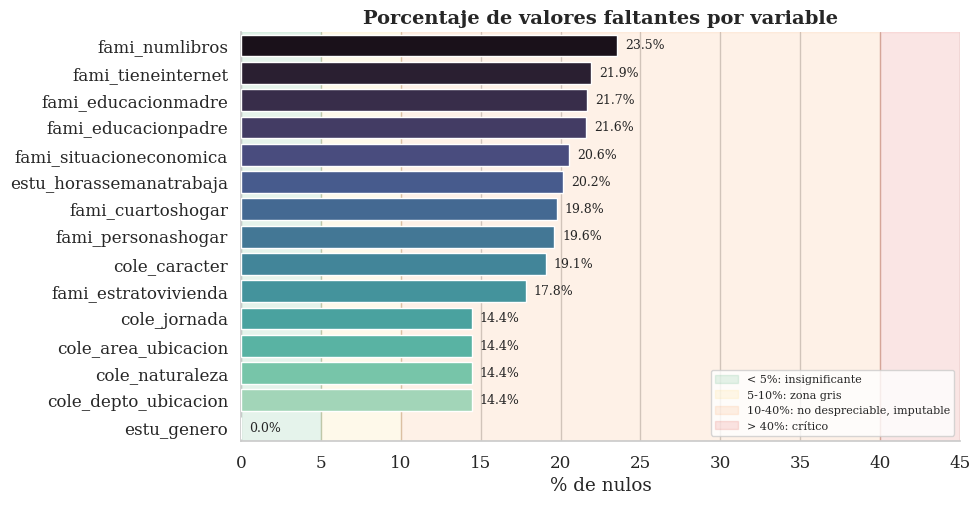

In [ ]:
pct_nulos = (df.isnull().mean() * 100).sort_values(ascending=False)
pct_nulos = pct_nulos[pct_nulos > 0]

fig, ax = plt.subplots(figsize=(10, max(4, len(pct_nulos)*0.35)))

ax.axvspan(0, 5, color="#2ca25f", alpha=0.12, label="< 5%: insignificante")
ax.axvspan(5, 10, color="#fed976", alpha=0.15, label="5-10%: zona gris")
ax.axvspan(10, 40, color="#fd8d3c", alpha=0.12, label="10-40%: no despreciable, imputable")
ax.axvspan(40, max(45, pct_nulos.max()+5), color="#de2d26", alpha=0.12, label="> 40%: crítico")

sns.barplot(x=pct_nulos.values, y=pct_nulos.index, hue=pct_nulos.index,
            palette="mako", legend=False, ax=ax, zorder=3)

for i, v in enumerate(pct_nulos.values):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=9, zorder=4)

ax.set_title("Porcentaje de valores faltantes por variable", fontsize=14, fontweight="bold")
ax.set_xlabel("% de nulos")
ax.set_ylabel("")
ax.set_xlim(0, max(45, pct_nulos.max()+8))
ax.legend(frameon=True, loc="lower right", fontsize=8)
sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
#Imputación de los valores nulos creando nueva categoría
cols_categoricas = [
    "cole_depto_ubicacion",
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_situacioneconomica",
    "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter", "cole_jornada",
    "estu_genero", "estu_horassemanatrabaja",
]

for col in cols_categoricas:
    df[col] = df[col].fillna("No reporta")
df[cols_categoricas].isnull().sum()

,0
cole_depto_ubicacion,0
fami_estratovivienda,0
fami_educacionmadre,0
fami_educacionpadre,0
fami_numlibros,0
fami_tieneinternet,0
fami_situacioneconomica,0
fami_personashogar,0
fami_cuartoshogar,0
cole_naturaleza,0


In [ ]:
#Si el puntaje global de un estudiante es nulo, se elimina la fila porque no es relevante para el estudio
print("Filas con punt_global nulo:", df["punt_global"].isnull().sum())
df = df.dropna(subset=["punt_global"]).reset_index(drop=True)

Filas con punt_global nulo: 0


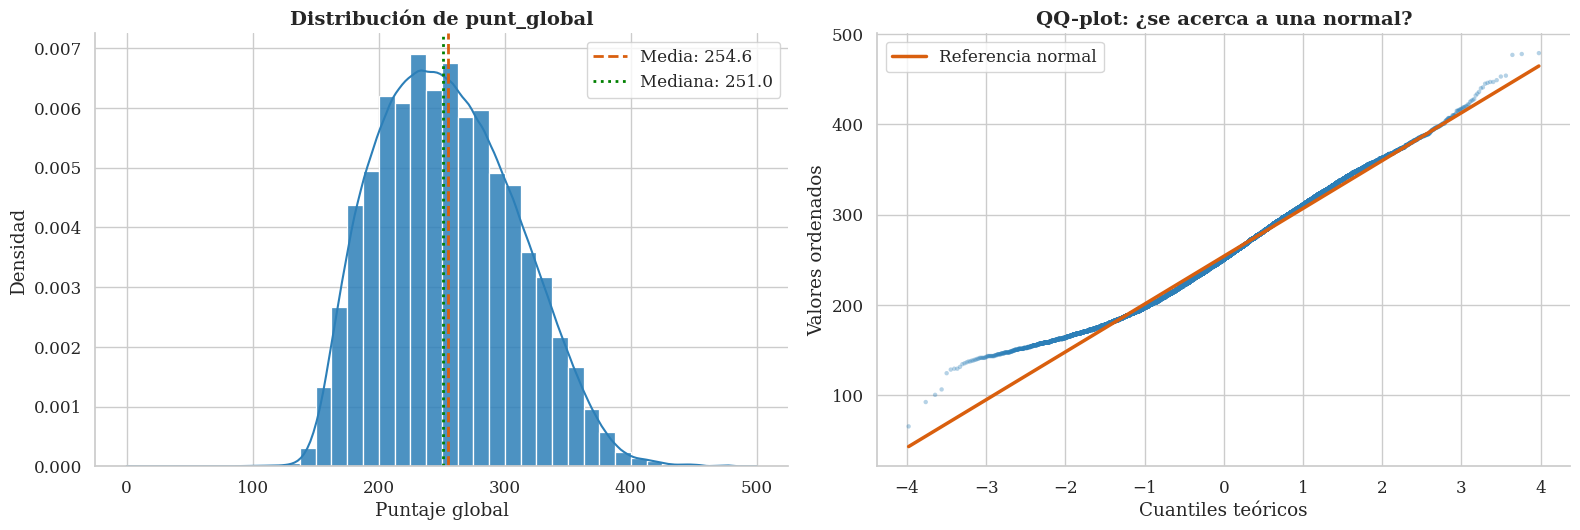

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16,5.5))

sns.histplot(df["punt_global"], kde=True, bins=40, stat="density",
             color=color_acento, edgecolor="white", alpha=0.85, ax=axes[0])
axes[0].axvline(df["punt_global"].mean(), color=color_secundario, linestyle="--",
                 linewidth=2, label=f"Media: {df['punt_global'].mean():.1f}")
axes[0].axvline(df["punt_global"].median(), color="green", linestyle=":",
                 linewidth=2, label=f"Mediana: {df['punt_global'].median():.1f}")
axes[0].set_title("Distribución de punt_global", fontsize=14, fontweight="bold")
axes[0].set_xlabel("Puntaje global")
axes[0].set_ylabel("Densidad")
axes[0].legend(frameon=True)

muestra_qq = df["punt_global"].dropna().sample(n=20000, random_state=42)
(cuantiles_teoricos, cuantiles_muestra), (pendiente, intercepto, r) = stats.probplot(muestra_qq, dist="norm")

axes[1].scatter(cuantiles_teoricos, cuantiles_muestra,
                 color=color_acento, s=10, alpha=0.35, edgecolor="none")
axes[1].plot(cuantiles_teoricos, pendiente*cuantiles_teoricos + intercepto,
              color=color_secundario, linewidth=2.5, label="Referencia normal")
axes[1].set_title("QQ-plot: ¿se acerca a una normal?", fontsize=14, fontweight="bold")
axes[1].set_xlabel("Cuantiles teóricos")
axes[1].set_ylabel("Valores ordenados")
axes[1].legend(frameon=True)

sns.despine()
plt.tight_layout()
plt.show()

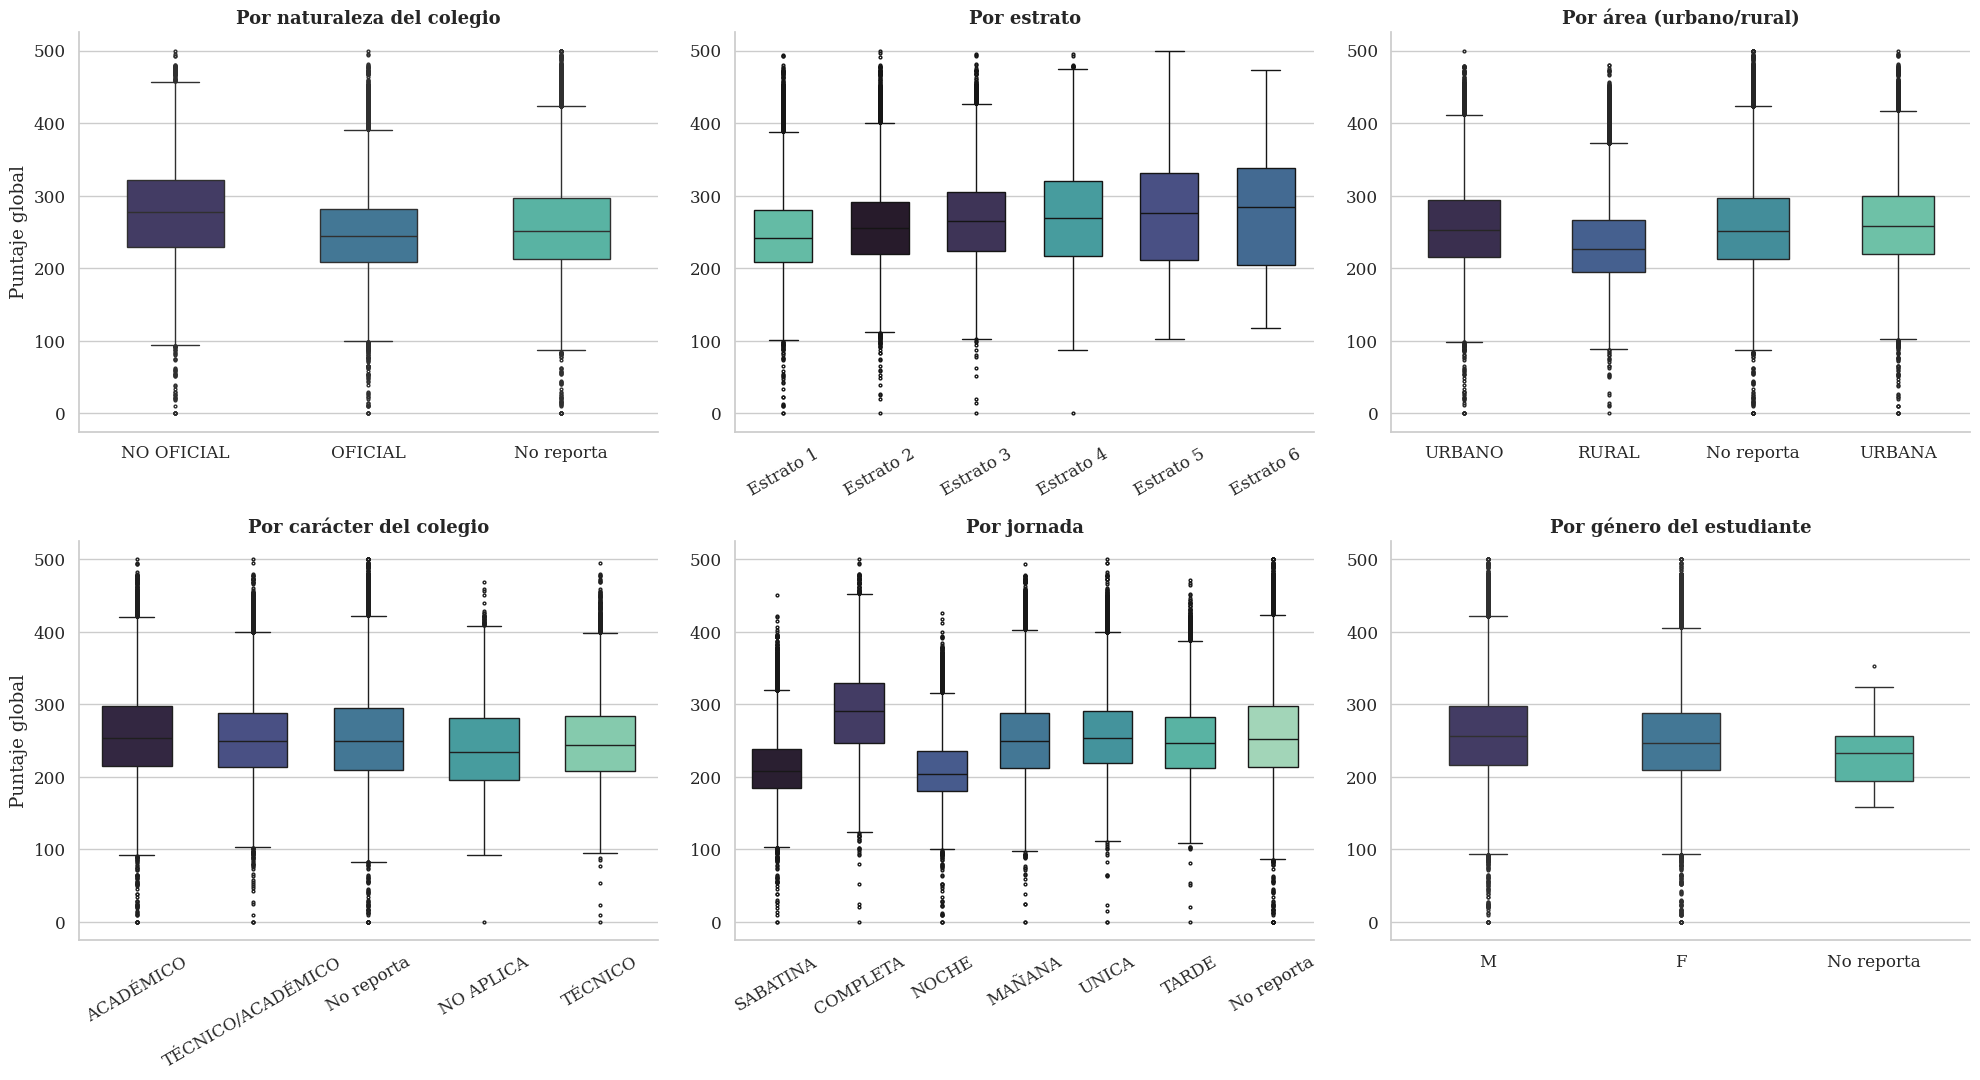

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20,11))

sns.boxplot(x="cole_naturaleza", y="punt_global", hue="cole_naturaleza", data=df, ax=axes[0,0],
            palette="mako", width=0.5, fliersize=2, legend=False)
axes[0,0].set_title("Por naturaleza del colegio", fontsize=13, fontweight="bold")
axes[0,0].set_xlabel(""); axes[0,0].set_ylabel("Puntaje global")

orden_estrato = ["Estrato 1", "Estrato 2", "Estrato 3", "Estrato 4", "Estrato 5", "Estrato 6"]
sns.boxplot(x="fami_estratovivienda", y="punt_global", hue="fami_estratovivienda", data=df, ax=axes[0,1],
            order=orden_estrato, palette="mako", width=0.6, fliersize=2, legend=False)
axes[0,1].set_title("Por estrato", fontsize=13, fontweight="bold")
axes[0,1].set_xlabel(""); axes[0,1].set_ylabel("")
axes[0,1].tick_params(axis='x', rotation=30)

sns.boxplot(x="cole_area_ubicacion", y="punt_global", hue="cole_area_ubicacion", data=df, ax=axes[0,2],
            palette="mako", width=0.5, fliersize=2, legend=False)
axes[0,2].set_title("Por área (urbano/rural)", fontsize=13, fontweight="bold")
axes[0,2].set_xlabel(""); axes[0,2].set_ylabel("")

sns.boxplot(x="cole_caracter", y="punt_global", hue="cole_caracter", data=df, ax=axes[1,0],
            palette="mako", width=0.6, fliersize=2, legend=False)
axes[1,0].set_title("Por carácter del colegio", fontsize=13, fontweight="bold")
axes[1,0].set_xlabel(""); axes[1,0].set_ylabel("Puntaje global")
axes[1,0].tick_params(axis='x', rotation=30)

sns.boxplot(x="cole_jornada", y="punt_global", hue="cole_jornada", data=df, ax=axes[1,1],
            palette="mako", width=0.6, fliersize=2, legend=False)
axes[1,1].set_title("Por jornada", fontsize=13, fontweight="bold")
axes[1,1].set_xlabel(""); axes[1,1].set_ylabel("")
axes[1,1].tick_params(axis='x', rotation=30)

sns.boxplot(x="estu_genero", y="punt_global", hue="estu_genero", data=df, ax=axes[1,2],
            palette="mako", width=0.4, fliersize=2, legend=False)
axes[1,2].set_title("Por género del estudiante", fontsize=13, fontweight="bold")
axes[1,2].set_xlabel(""); axes[1,2].set_ylabel("")

sns.despine()
plt.tight_layout()
plt.show()

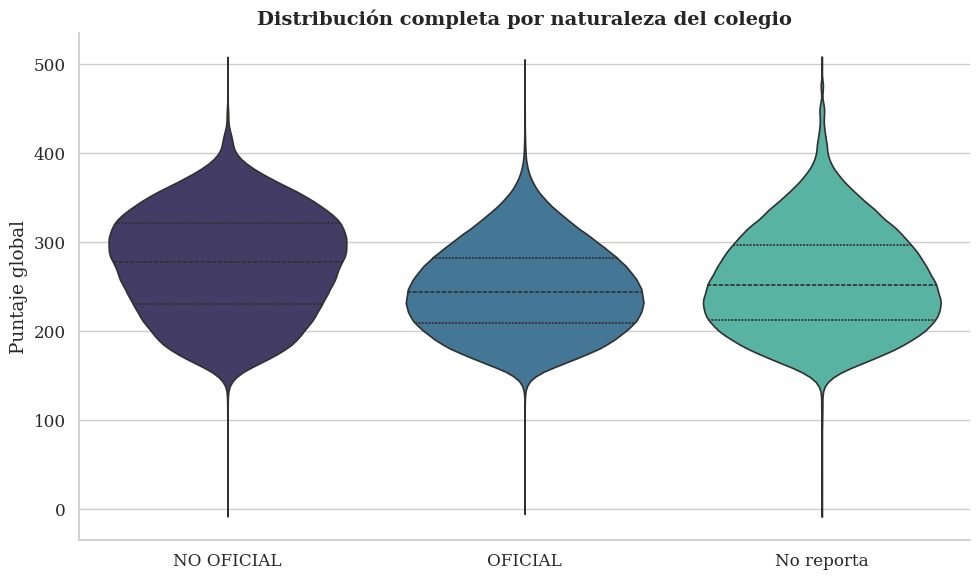

In [13]:
n_categorias = df["cole_naturaleza"].nunique()

plt.figure(figsize=(10,6))
ax = sns.violinplot(x="cole_naturaleza", y="punt_global", hue="cole_naturaleza", data=df,
                     palette=sns.color_palette("mako", n_colors=n_categorias),
                     inner="quartile", linewidth=1.2, legend=False)
ax.set_title("Distribución completa por naturaleza del colegio", fontsize=14, fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("Puntaje global")
sns.despine()
plt.tight_layout()
plt.show()

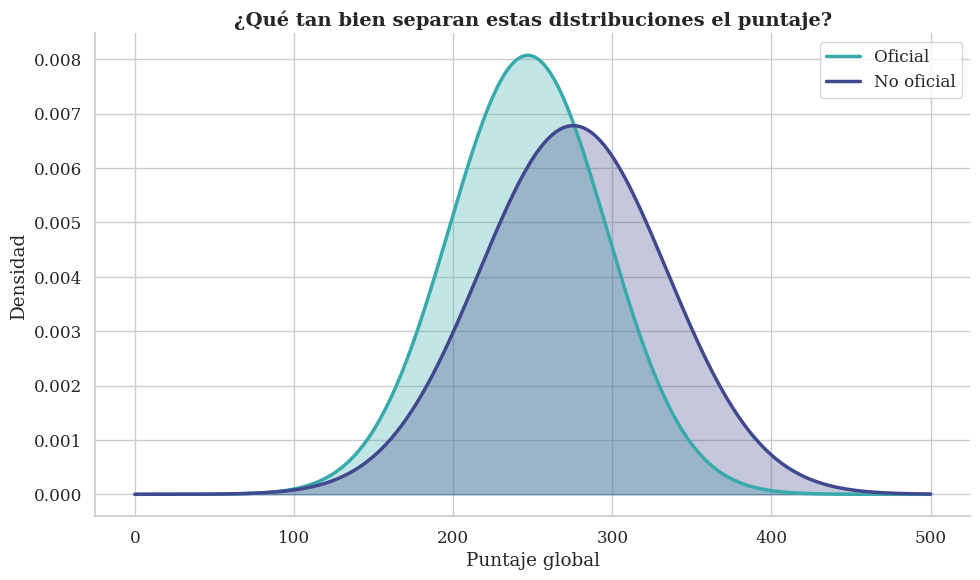

In [16]:
colores_mako = sns.color_palette("mako", n_colors=2)

p_oficial = df.punt_global[df.cole_naturaleza == "OFICIAL"].dropna()
p_no_oficial = df.punt_global[df.cole_naturaleza == "NO OFICIAL"].dropna()

dist_oficial = stats.norm(loc=np.mean(p_oficial), scale=np.std(p_oficial))
dist_no_oficial = stats.norm(loc=np.mean(p_no_oficial), scale=np.std(p_no_oficial))

t = np.linspace(min(p_oficial.min(), p_no_oficial.min()), max(p_oficial.max(), p_no_oficial.max()), 300)

plt.figure(figsize=(10,6))
plt.plot(t, dist_oficial.pdf(t), color=colores_mako[1], linewidth=2.5, label="Oficial")
plt.fill_between(t, dist_oficial.pdf(t), color=colores_mako[1], alpha=0.3)

plt.plot(t, dist_no_oficial.pdf(t), color=colores_mako[0], linewidth=2.5, label="No oficial")
plt.fill_between(t, dist_no_oficial.pdf(t), color=colores_mako[0], alpha=0.3)

plt.title("¿Qué tan bien separan estas distribuciones el puntaje?", fontsize=14, fontweight="bold")
plt.xlabel("Puntaje global"); plt.ylabel("Densidad")
plt.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

Nulos en hacinamiento: 534975


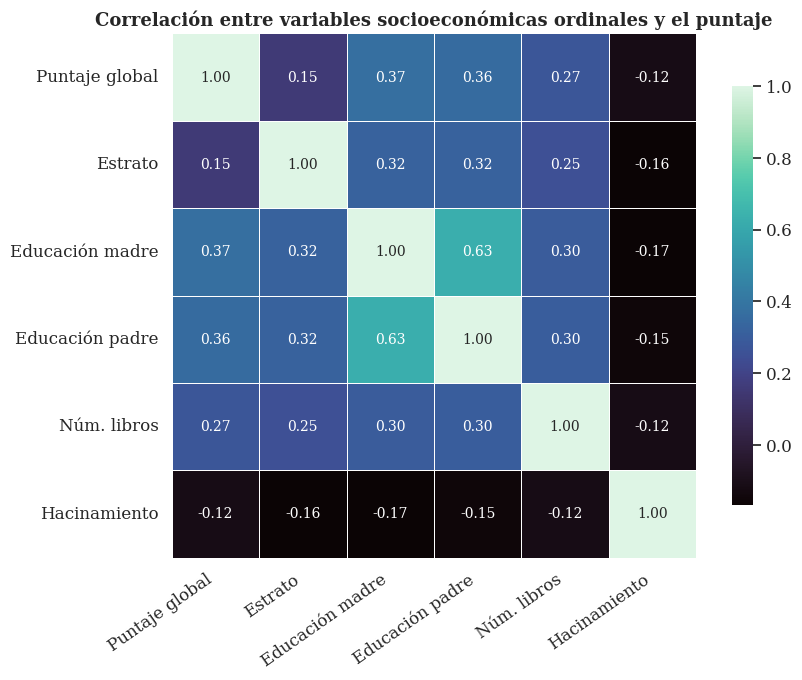

In [21]:

mapa_estrato = {
    "Sin Estrato": None, "Estrato 1": 1, "Estrato 2": 2, "Estrato 3": 3,
    "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6
}

mapa_educacion = {
    "No sabe": None, "No Aplica": None, "Ninguno": 0,
    "Primaria incompleta": 1, "Primaria completa": 2,
    "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
    "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
    "Educación profesional incompleta": 7, "Educación profesional completa": 8,
    "Postgrado": 9
}

mapa_libros = {
    "0 A 10 LIBROS": 0, "11 A 25 LIBROS": 1,
    "26 A 100 LIBROS": 2, "MÁS DE 100 LIBROS": 3
}

mapa_personas = {
    "1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9,
    "No reporta": None,
}

mapa_cuartos = {
    "Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6,
    "No reporta": None,
}


df["personas_num"] = df["fami_personashogar"].map(mapa_personas)
df["cuartos_num"] = df["fami_cuartoshogar"].map(mapa_cuartos)
df["hacinamiento"] = df["personas_num"] / df["cuartos_num"]

print("Nulos en hacinamiento:", df["hacinamiento"].isnull().sum())


df_num = pd.DataFrame({
    "Puntaje global": df["punt_global"],
    "Estrato": df["fami_estratovivienda"].map(mapa_estrato),
    "Educación madre": df["fami_educacionmadre"].map(mapa_educacion),
    "Educación padre": df["fami_educacionpadre"].map(mapa_educacion),
    "Núm. libros": df["fami_numlibros"].map(mapa_libros),
    "Hacinamiento": df["hacinamiento"],
})

# --- 4. Heatmap ---
plt.figure(figsize=(9,7))
corr = df_num.corr()

sns.heatmap(corr, annot=True, fmt=".2f", cmap="mako",
            linewidths=0.6, linecolor="white", cbar_kws={"shrink": 0.8},
            square=True, annot_kws={"fontsize": 10})

plt.title("Correlación entre variables socioeconómicas ordinales y el puntaje",
          fontsize=13, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()